# IR Practical 3: Agglomerative Hierarchical Clustering

In [1]:
%pip install -q kagglehub numpy pandas matplotlib scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

print("Downloading Credit Card dataset...")
path = kagglehub.dataset_download("arjunbhasin2013/ccdata")
print("Dataset folder:", path)

csv_path = None
for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower() == "cc_general.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

if csv_path is None:
    for root, dirs, files in os.walk(path):
        csv_files = [
            f for f in files if f.lower().endswith(".csv")
        ]
        if csv_files:
            csv_path = os.path.join(root, csv_files[0])
            break

if csv_path is None:
    raise FileNotFoundError("No CSV file found in the dataset.")

print("Using file:", csv_path)
data = pd.read_csv(csv_path)

print("\nOriginal dataset:")
print(data.head())
print("\nDataset shape:", data.shape)

c:\Users\anjal\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 340k/340k [00:02<00:00, 167kB/s]

Extracting files...
Dataset folder: C:\Users\anjal\.cache\kagglehub\datasets\arjunbhasin2013\ccdata\versions\1
Using file: C:\Users\anjal\.cache\kagglehub\datasets\arjunbhasin2013\ccdata\versions\1\CC GENERAL.csv

Original dataset:
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4  

In [3]:
# Remove customer ID because it is not a useful
# numerical feature for measuring customer similarity.
if "CUST_ID" in data.columns:
    data = data.drop("CUST_ID", axis=1)

# Convert all feature columns to numeric values
data = data.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
data = data.replace([np.inf, -np.inf], np.nan)

# Fill missing values with each column's median
data = data.fillna(data.median())

# Remove any columns that contain no usable values
data = data.dropna(axis=1, how="all")

print("\nMissing values after cleaning:")
print(data.isnull().sum().sum())
print("\nCleaned dataset shape:", data.shape)


Missing values after cleaning:
0

Cleaned dataset shape: (8950, 17)


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# Normalize each customer's feature vector
X_normalized = normalize(X_scaled)
print("\nScaling and normalization completed.")


Scaling and normalization completed.


In [5]:
# Reduce the data to two dimensions for visualization
pca = PCA(n_components=2, random_state=42)
X_principal = pca.fit_transform(X_normalized)
X_principal = pd.DataFrame(
    X_principal,
    columns=["P1", "P2"]
)

print("\nPCA completed.")
print("Explained variance ratio:", pca.explained_variance_ratio_)


PCA completed.
Explained variance ratio: [0.29045124 0.18403609]


In [6]:
# Hierarchical clustering and dendrograms can be expensive
# on large datasets. Use a reproducible sample if necessary.
max_samples = 1500
if len(X_principal) > max_samples:
    X_sample = X_principal.sample(
        n=max_samples,
        random_state=42
    ).reset_index(drop=True)
else:
    X_sample = X_principal.reset_index(drop=True)

print("\nNumber of customers used for clustering:", len(X_sample))


Number of customers used for clustering: 1500


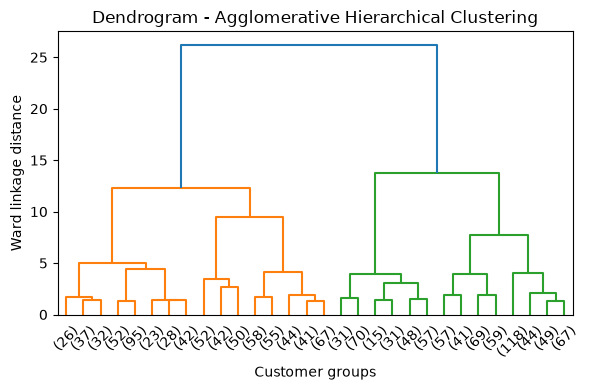

In [7]:
plt.figure(figsize=(6, 4))
linkage_matrix = linkage(
    X_sample[["P1", "P2"]],
    method="ward"
)
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30
)
plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Customer groups")
plt.ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

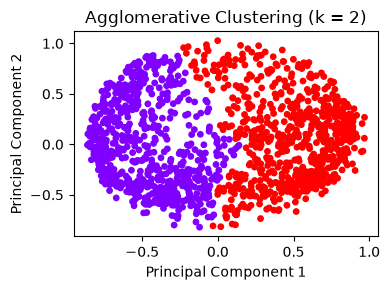


Number of clusters: 2
Cluster sizes:
0    756
1    744
Name: count, dtype: int64
Silhouette score: 0.4461


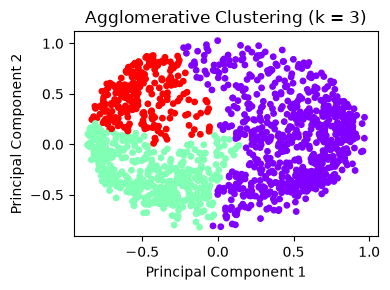


Number of clusters: 3
Cluster sizes:
0    744
1    504
2    252
Name: count, dtype: int64
Silhouette score: 0.4079


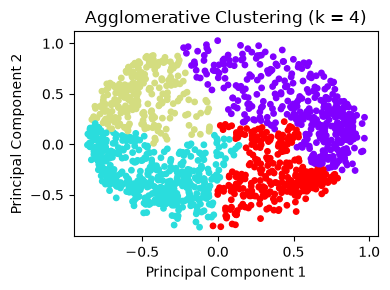


Number of clusters: 4
Cluster sizes:
0    409
1    504
2    252
3    335
Name: count, dtype: int64
Silhouette score: 0.3585


In [8]:
for k in [2, 3, 4]:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = model.fit_predict(X_sample[["P1", "P2"]])

    plt.figure(figsize=(4, 3))
    plt.scatter(
        X_sample["P1"],
        X_sample["P2"],
        c=labels,
        cmap="rainbow",
        s=15
    )
    plt.title(f"Agglomerative Clustering (k = {k})")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.show()

    score = silhouette_score(
        X_sample[["P1", "P2"]],
        labels
    )
    print(f"\nNumber of clusters: {k}")
    print("Cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())
    print(f"Silhouette score: {score:.4f}")

In [9]:
print("\nConclusion:")
print("Agglomerative hierarchical clustering completed.")
print("The dendrogram and PCA plots visualize customer groups.")
print("Compare cluster plots and silhouette scores to assess")
print("the grouping quality for k = 2, 3, and 4.")


Conclusion:
Agglomerative hierarchical clustering completed.
The dendrogram and PCA plots visualize customer groups.
Compare cluster plots and silhouette scores to assess
the grouping quality for k = 2, 3, and 4.
